<a href="https://colab.research.google.com/github/bisensamiksha/Samiksha_Task/blob/main/Assignment_1_Samiksha_Loksingh_Bisen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task B

Task B: NumPy Gradient Descent

B1:
η is a multiplier not the distance moved. The step size depends on both ηt and the size of gradient i.e. ηt||∇f(xt)||. A steeper slope produce a larger step for the same ηt.

B2:

Approach 1: Stop when we have reached maximum number of iterations. Pros of this is that it avoids infinite loop and con is that we cannot say we have reached the minima.

Approch 2: Stop when the gradient is less than threshold. It is useful when there is less gradient or almost flat function. It might not garantee minima.

Approch 3: Stop when the position remains almost constant between steps. It can be used to show that the search seems to have settled down. But it can happen when η is very small and doesn't garantee minima.

To find the non-convergence, I would go ahead with maximum number of iterations approach. If by the end of the iteretions:
- If the gradient is still large, the search probably hasn’t settled at a flat point.
- If the function value keeps rising or jumping around, the search may be unstable.
- If positions grow extremely large, or results become inf or NaN (not a number), the search may be diverging.


B3:

(a) Choose a starting value x0, step size eta, threshold, and maximum number of steps.

Set x = x0.

For each step, up to the maximum:

    Calculate f(x) = -exp(-(x - 3.14)^2)
    Calculate the slope = 2(x - 3.14) * exp(-(x - 3.14)^2)

    If the absolute value of the slope is less than threshold:
        Stop; report x and f(x).

    Update x = x - eta * slope

If the maximum number of steps is reached:

    Report the current x and f(x), and say the step limit was reached.


(b) On the interval \([0,6]\), the graph dips to its lowest point at \(x=3.14\), where its value is \(-1\). Yes, we can predict this from the formula because the squared expression $(x-3.14)^2$ is smallest at \(x=3.14\).

Minimum position: 3.139595440174916
Function value there: -0.9999998363313614
Steps taken: 42


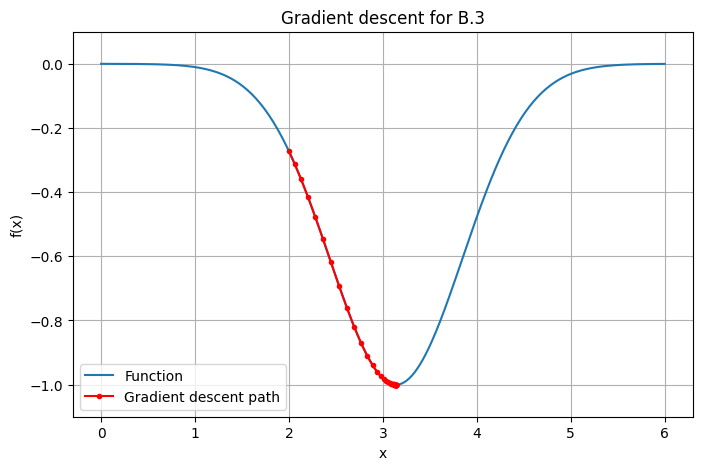

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# The function and its derivative (slope)
def f(x):
    return -np.exp(-(x - 3.14)**2)

def derivative(x):
    return 2 * (x - 3.14) * np.exp(-(x - 3.14)**2)

# Starting guess and search settings
x = 2.0
eta = 0.1
max_steps = 1000
threshold = 0.001

# Save the starting point so we can plot the search path
trajectory_x = [x]
trajectory_f = [f(x)]

for step in range(max_steps):
    slope = derivative(x)

    # Stop if the slope is extremely small
    if abs(slope) < threshold:
        break

    # Take one downhill step
    x = x - eta * slope

    # Save this position and its function value
    trajectory_x.append(x)
    trajectory_f.append(f(x))

print("Minimum position:", x)
print("Function value there:", f(x))
print("Steps taken:", step + 1)

# Draw the function and overlay the search path
x_values = np.linspace(0, 6, 400)

plt.figure(figsize=(8, 5))
plt.plot(x_values, f(x_values), label="Function")
plt.plot(trajectory_x, trajectory_f, "ro-", markersize=3,
         label="Gradient descent path")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Gradient descent for B.3")
plt.ylim(-1.1, 0.1)
plt.grid(True)
plt.legend()
plt.show()

(e) To find maxima, we can update the  "x = x - eta * slope"  to   "x = x + eta * slope"  in the above code.

# Task C

C1: I learned that PyTorch tensors can track how a calculation depends on its inputs. By setting `requires_grad=True` and calling `.backward()`, PyTorch calculates the derivative and stores it in `.grad`. This will be useful for gradient descent, where derivatives guide each step toward a minimum.

C2:

In [1]:
import torch

# Define the function using PyTorch operations
def f(x):
    return 3 * torch.pow(x, 2) + 1

# Tell PyTorch to track how the result depends on x
x0 = torch.tensor(2.0, requires_grad=True)

# Calculate the function value
fx0 = f(x0)
print("Function value:", fx0.item())

# Calculate the derivative
fx0.backward()
print("Slope at x = 2:", x0.grad.item())

Function value: 13.0
Slope at x = 2: 12.0


C3: 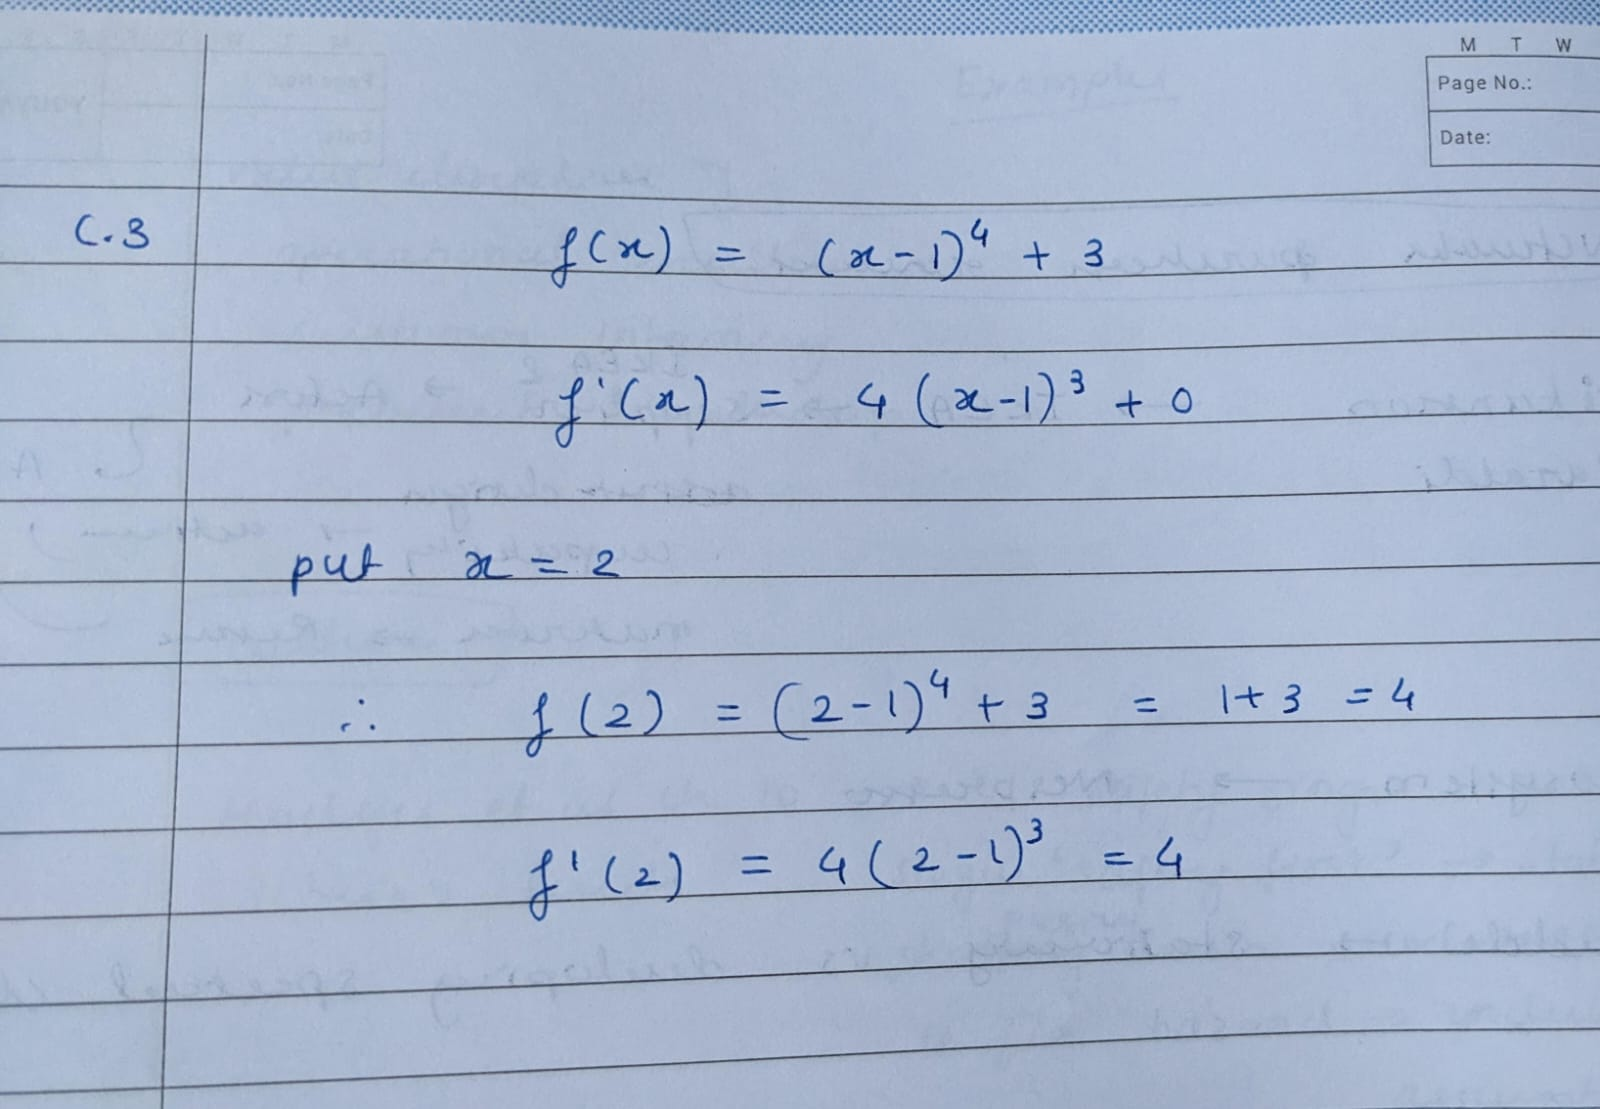

Solving manually resulted in f'(x) = 4(x-1)^3 and f'(2) = 4

In [5]:
import torch

def f(x):
  return torch.pow(x-1, 4) + 3


x0 = torch.tensor(2.0, requires_grad=True)
fx0 = f(x0)

fx0.backward()

print("Slope at x = 2:", x0.grad.item())


Slope at x = 2: 4.0


C4: By hand 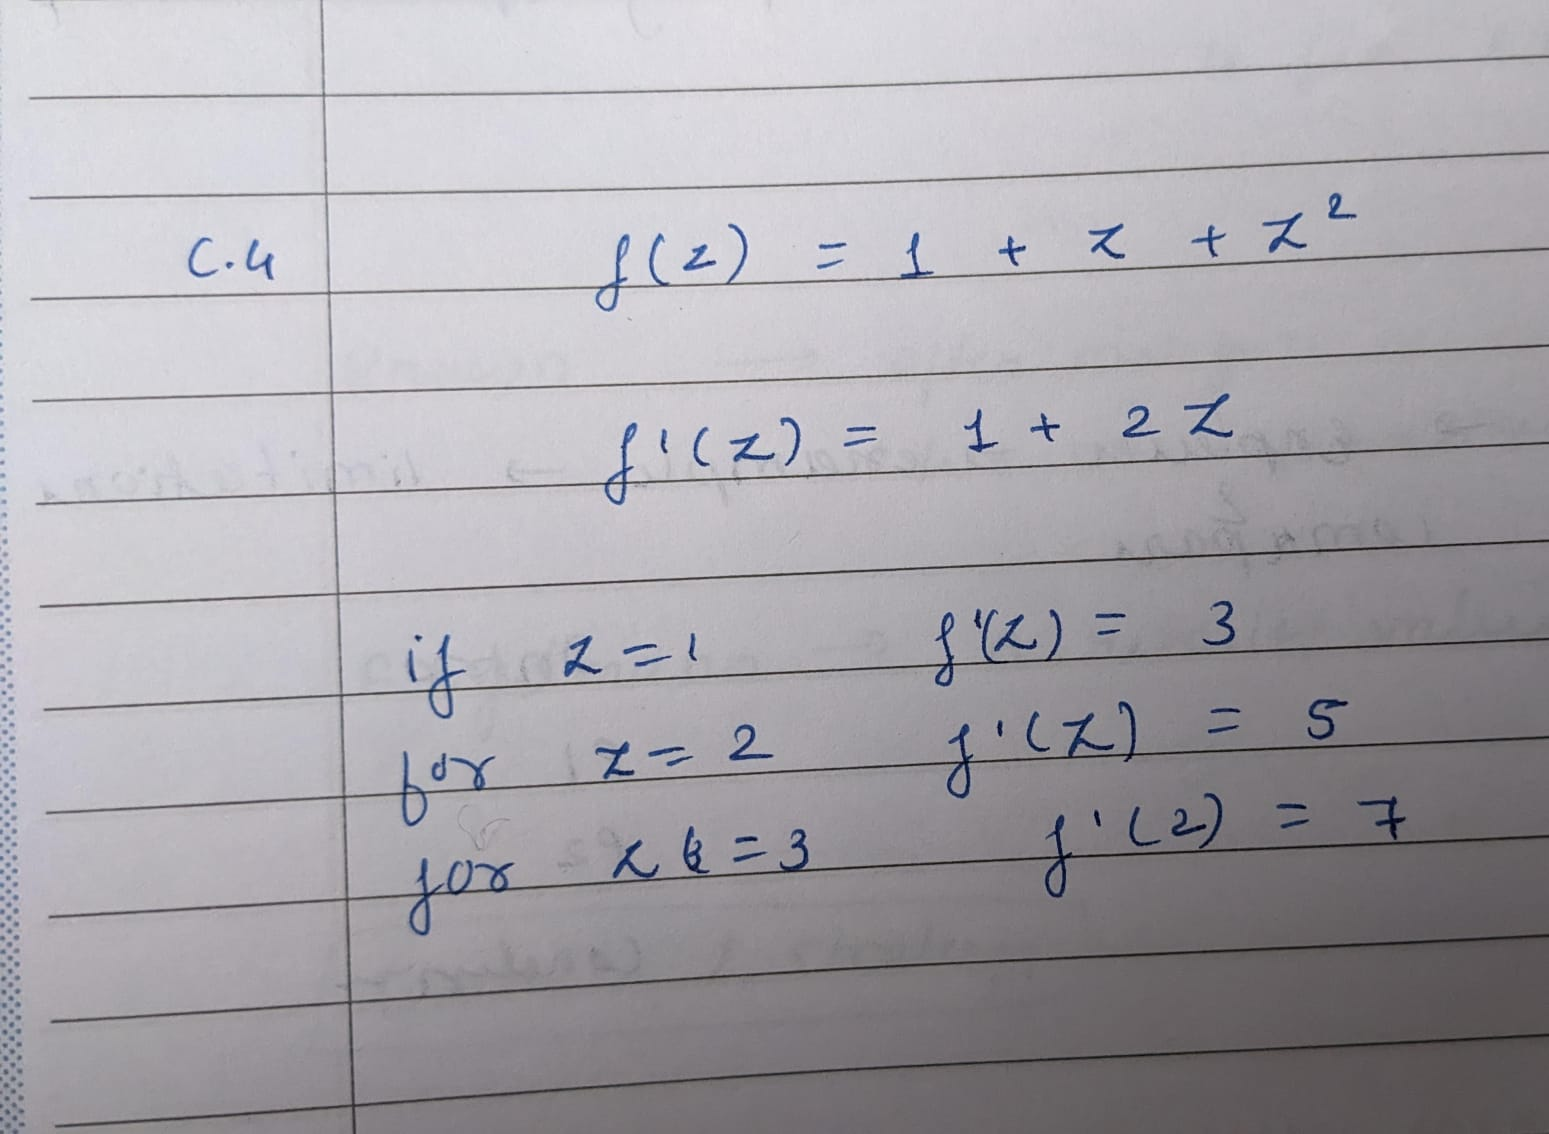

In [6]:
import torch

def f_loop(z):
    result = 0
    for n in range(3):
        result = result + torch.pow(z, n)
    return result

for z_value in [1.0, 2.0, 3.0]:
    z = torch.tensor(z_value, requires_grad=True)
    value = f_loop(z)
    value.backward()

    print(
        "z:", z_value,
        "function value:", value.item(),
        "slope:", z.grad.item()
    )

z: 1.0 function value: 3.0 slope: 3.0
z: 2.0 function value: 7.0 slope: 5.0
z: 3.0 function value: 13.0 slope: 7.0


C5: Calculations by hand

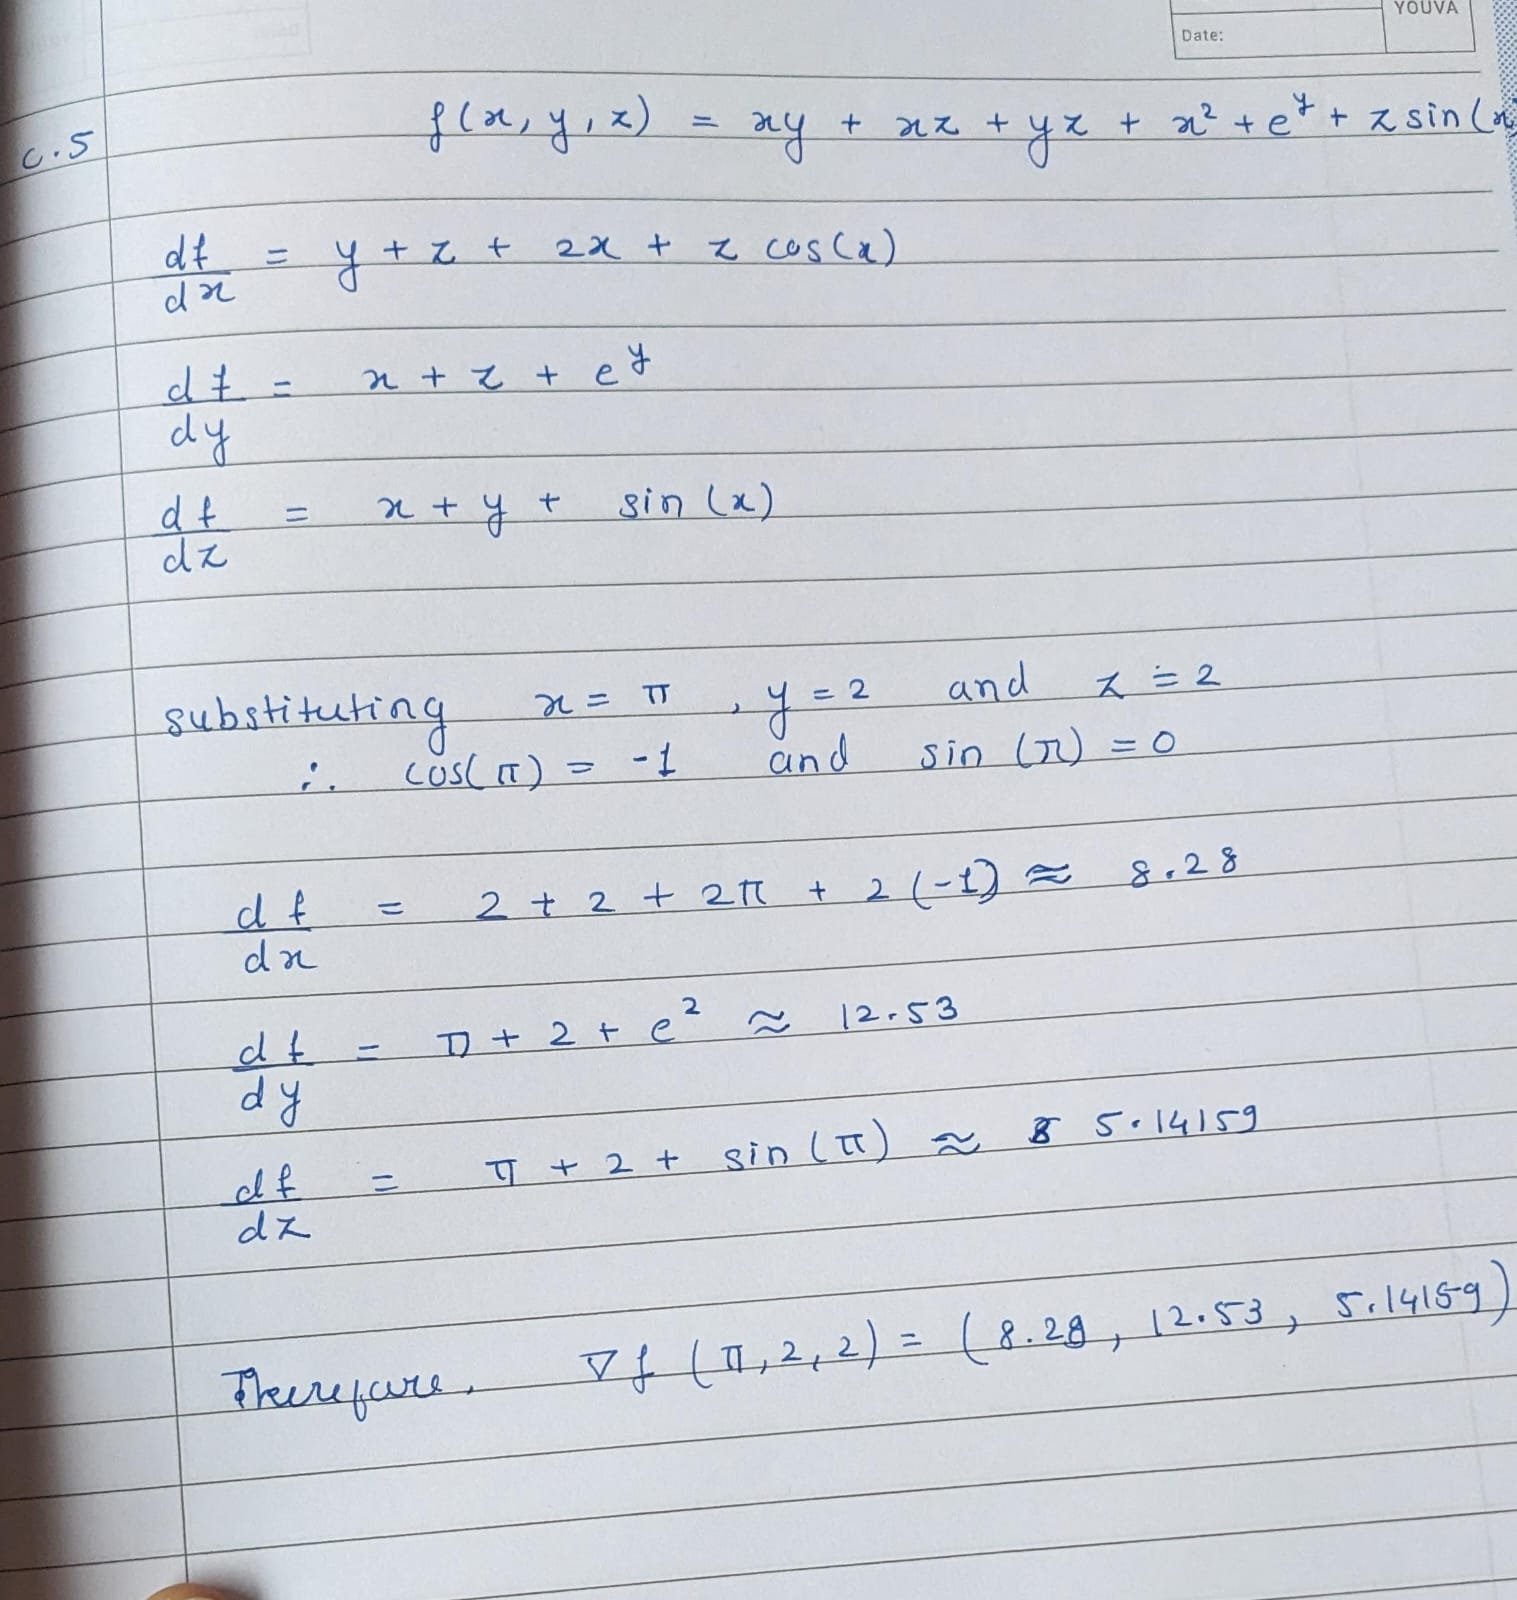

In [13]:
import math
import torch

def f(x, y, z):
    return x*y + x*z + y*z + x**2 + torch.exp(y) + z*torch.sin(x)

x0 = torch.tensor(math.pi, requires_grad=True)
y0 = torch.tensor(2.0, requires_grad=True)
z0 = torch.tensor(2.0, requires_grad=True)

value = f(x0, y0, z0)
value.backward()

print("Slope for x:", x0.grad.item())
print("Slope for y:", y0.grad.item())
print("Slope for z:", z0.grad.item())

Slope for x: 8.283185958862305
Slope for y: 12.530649185180664
Slope for z: 5.141592502593994


C6: Calculations by hand 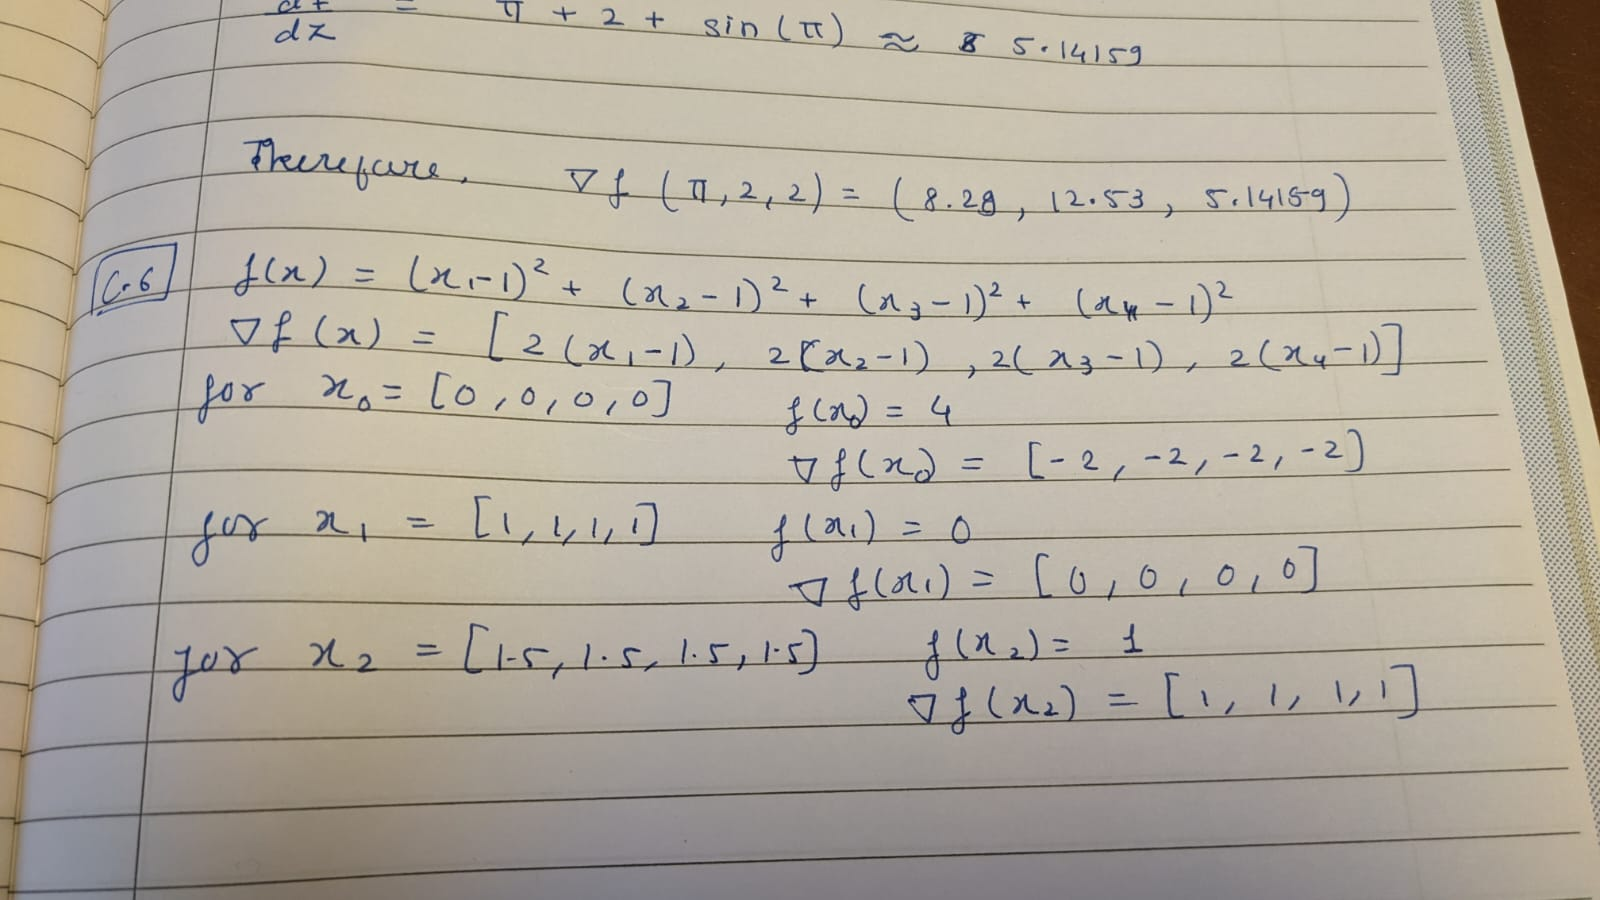

In [14]:
import torch

def f(x):
    one_vector = torch.ones_like(x)
    difference = x - one_vector
    return torch.dot(difference, difference)

points = {
    "x0": [0.0, 0.0, 0.0, 0.0],
    "x1": [1.0, 1.0, 1.0, 1.0],
    "x2": [1.5, 1.5, 1.5, 1.5]
}

for name, values in points.items():
    x = torch.tensor(values, requires_grad=True)
    fx = f(x)
    fx.backward()

    print(name, "function value:", fx.item(), "gradient:", x.grad.tolist())

x0 function value: 4.0 gradient: [-2.0, -2.0, -2.0, -2.0]
x1 function value: 0.0 gradient: [0.0, 0.0, 0.0, 0.0]
x2 function value: 1.0 gradient: [1.0, 1.0, 1.0, 1.0]


# Task D

D1 Solution

eta=1.0: x=3.241844, f(x)=-0.989899
eta=0.1: x=3.141593, f(x)=-1.000000
eta=0.01: x=0.593182, f(x)=0.063432


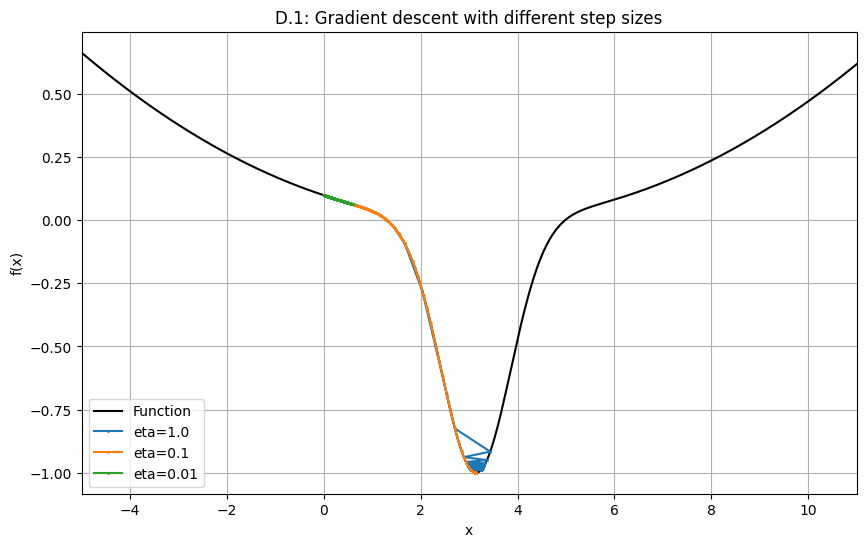

In [23]:
import math
import numpy as np
import torch
import matplotlib.pyplot as plt

def f_torch(x):
    return -torch.exp(-((x - math.pi) ** 2)) + 0.01 * (x - math.pi) ** 2

def run_gradient_descent(eta, x_start=0.0, steps=1000):
    x = torch.tensor(x_start, dtype=torch.float64, requires_grad=True)
    trajectory_x = []
    trajectory_f = []

    for _ in range(steps):
        value = f_torch(x)
        trajectory_x.append(x.item())
        trajectory_f.append(value.item())

        value.backward()

        # Update x without asking PyTorch to track the update itself
        with torch.no_grad():
            x -= eta * x.grad
            x.grad.zero_()

    # Save the final position too
    with torch.no_grad():
        final_x = x.item()
        final_f = f_torch(x).item()
        trajectory_x.append(final_x)
        trajectory_f.append(final_f)

    print(f"eta={eta}: x={final_x:.6f}, f(x)={final_f:.6f}")
    return trajectory_x, trajectory_f

# Draw the function over the requested interval
x_plot = np.linspace(-5, 11, 500)
y_plot = -np.exp(-((x_plot - np.pi) ** 2)) + 0.01 * (x_plot - np.pi) ** 2

plt.figure(figsize=(10, 6))
plt.plot(x_plot, y_plot, color="black", label="Function")

# Run all three step sizes from the same starting point
for eta in [1.0, 0.1, 0.01]:
    path_x, path_f = run_gradient_descent(eta, x_start=0.0, steps=1000)
    plt.plot(path_x, path_f, marker=".", markersize=2, label=f"eta={eta}")

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("D.1: Gradient descent with different step sizes")
plt.xlim(-5, 11)
plt.grid(True)
plt.legend()
plt.show()

D2 Solution


eta=0.01: final point=(2.9976, 0.6738), function value=1.758818
eta=0.03: final point=(3.0000, 1.9795), function value=0.000422
eta=0.1: final point=(3.0000, 2.0000), function value=0.000000
eta=1.0: final point=(-32344765096247587305539763564804223060714243349828055209022503504074307804688715612160.0000, -8.0000), function value=4184735316525744360061966417355890164088936554089845357810972575468030218701209308340175813229076798825443381268385052739065380752966009441897544673792061451741305239502848.000000


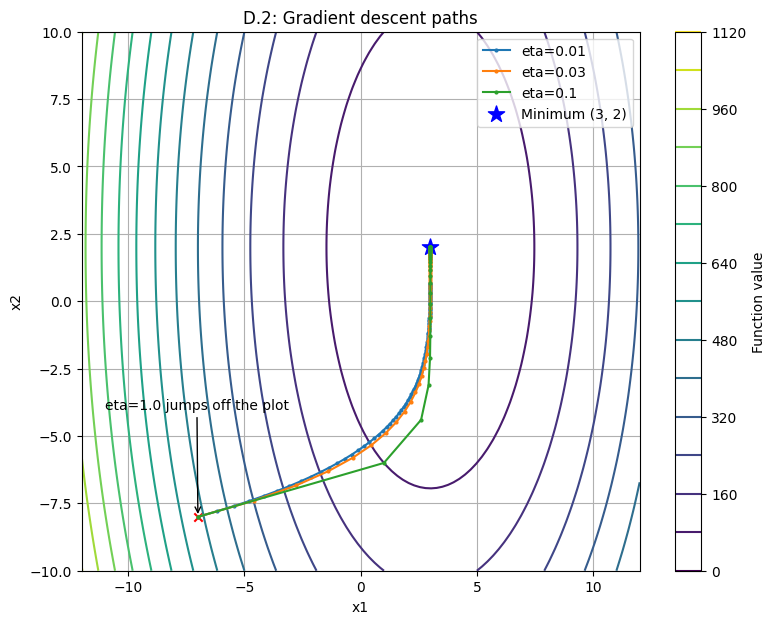

In [26]:
import numpy as np
import torch
import matplotlib.pyplot as plt

def f_torch(x):
    x1 = x[0]
    x2 = x[1]
    return 4 * (x1 - 3)**2 + (x2 - 2)**2

def run_gradient_descent(eta, n_steps=100):
    x = torch.tensor([-7.0, -8.0], dtype=torch.float64, requires_grad=True)
    path = [x.detach().numpy().copy()]

    for _ in range(n_steps):
        value = f_torch(x)
        value.backward()

        with torch.no_grad():
            x -= eta * x.grad
            x.grad.zero_()

        path.append(x.detach().numpy().copy())

    return np.array(path), x.detach().numpy(), f_torch(x).item()

etas = [0.01, 0.03, 0.1, 1.0]
results = {}

for eta in etas:
    path, final_x, final_value = run_gradient_descent(eta)
    results[eta] = path
    print(
        f"eta={eta}: final point=({final_x[0]:.4f}, {final_x[1]:.4f}), "
        f"function value={final_value:.6f}"
    )

# Make a contour map of the function
x_values = np.linspace(-12, 12, 100)
y_values = np.linspace(-10, 10, 100)
X, Y = np.meshgrid(x_values, y_values)
Z = 4 * (X - 3)**2 + (Y - 2)**2

plt.figure(figsize=(9, 7))
contours = plt.contour(X, Y, Z, levels=15, cmap="viridis")
plt.colorbar(contours, label="Function value")

for eta, path in results.items():
    inside_plot = (
        (path[:, 0] >= -12) & (path[:, 0] <= 12) &
        (path[:, 1] >= -10) & (path[:, 1] <= 10)
    )

    visible_path = path[inside_plot]

    if len(visible_path) > 1:
        plt.plot(
            visible_path[:, 0], visible_path[:, 1],
            marker=".", markersize=4, label=f"eta={eta}"
        )
    else:
        plt.scatter(-7, -8, color="red", marker="x")
        plt.annotate(
            "eta=1.0 jumps off the plot",
            xy=(-7, -8), xytext=(-11, -4),
            arrowprops={"arrowstyle": "->"}
        )

plt.scatter(3, 2, color="blue", marker="*", s=150, label="Minimum (3, 2)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("D.2: Gradient descent paths")
plt.legend()
plt.grid(True)
plt.show()

To compare effect of various values of eta, I have used 100 steps iteration. For these starting values and 100 steps, eta=0.1 gets closest to (3,2) without overshooting, eta=0.01 and eta = 0.03 make slower progress and, while eta=1 diverges. So I think ets=0.1 is a good value of eta for this.

D3:

(a)
In the plot below, we can see there are two minimas. Gradient decent works by identifying the gradient in one particular point and hence it might get settle in local minima and miss the global minima. It depends on the starting point we choose.

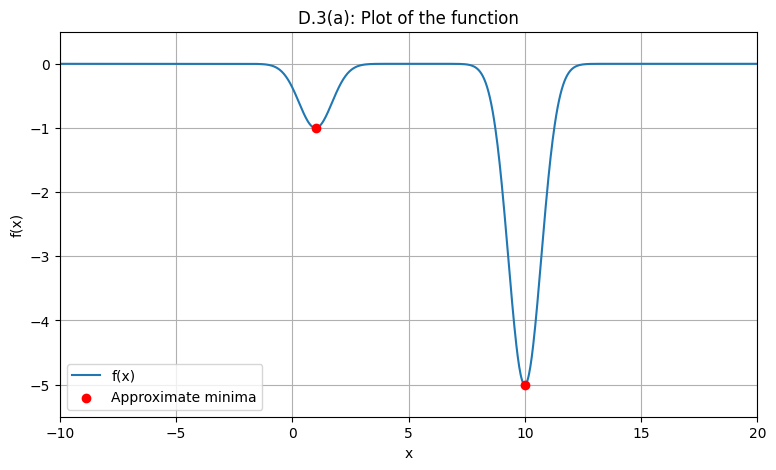

In [27]:
import numpy as np
import matplotlib.pyplot as plt

# Values of x across the requested interval
x = np.linspace(-10, 20, 1000)

# Calculate the function value for each x
y = -np.exp(-(x - 1)**2) - 5 * np.exp(-(x - 10)**2)

plt.figure(figsize=(9, 5))
plt.plot(x, y, label="f(x)")
plt.scatter([1, 10], [-1, -5], color="red", zorder=3,
            label="Approximate minima")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("D.3(a): Plot of the function")
plt.xlim(-10, 20)
plt.ylim(-5.5, 0.5)
plt.grid(True)
plt.legend()
plt.show()

(b) Implementation of function using PyTorch. It starts at (x=7) with (eta=0.1)

In [29]:
import torch

def f_torch(x):
    return -torch.exp(-((x - 1)**2)) - 5 * torch.exp(-((x - 10)**2))

def gradient_descent(x_start, eta, n_steps=1000):
    x = torch.tensor(float(x_start), dtype=torch.float64, requires_grad=True)

    trajectory_x = [x.item()]
    trajectory_f = [f_torch(x).item()]

    for _ in range(n_steps):
        value = f_torch(x)
        value.backward()  # PyTorch calculates the slope at the current x

        with torch.no_grad():
            x -= eta * x.grad  # take a downhill step
            x.grad.zero_()     # clear the old slope

            trajectory_x.append(x.item())
            trajectory_f.append(f_torch(x).item())

    return x.item(), f_torch(x).item(), trajectory_x, trajectory_f

# Example run; parts (d) and (e) ask you to try other settings too
final_x, final_value, trajectory_x, trajectory_f = gradient_descent(
    x_start=7.0,
    eta=0.1,
    n_steps=1000
)

print("Final x:", final_x)
print("Function value:", final_value)

Final x: 10.0
Function value: -5.0


(c) Based on the plot above, I would put starting location anywhere between 4 to 9 becasue since the global minima is at 10, if we start at 7, gradient decent will lead us to the global minima. Whereas if we choose a starting point less than 0, then we will get minima as -1 which is a local minima.

In [32]:
import torch

def f_torch(x):
    return -torch.exp(-((x - 1)**2)) - 5 * torch.exp(-((x - 10)**2))

def gradient_descent(x_start, eta, n_steps=1000):
    x = torch.tensor(float(x_start), dtype=torch.float64, requires_grad=True)

    trajectory_x = [x.item()]
    trajectory_f = [f_torch(x).item()]

    for _ in range(n_steps):
        value = f_torch(x)
        value.backward()  # PyTorch calculates the slope at the current x

        with torch.no_grad():
            x -= eta * x.grad  # take a downhill step
            x.grad.zero_()     # clear the old slope

            trajectory_x.append(x.item())
            trajectory_f.append(f_torch(x).item())

    return x.item(), f_torch(x).item(), trajectory_x, trajectory_f

# Example run; parts (d) and (e) ask you to try other settings too
final_x, final_value, trajectory_x, trajectory_f = gradient_descent(
    x_start=1.0,
    eta=0.1,
    n_steps=1000
)

print("Final x:", final_x)
print("Function value:", final_value)

Final x: 1.0
Function value: -1.0


(d) No, we don't get global minima both the time. We get local minima -1 for the starting value 3.

In [34]:
import torch

def f_torch(x):
    return -torch.exp(-((x - 1)**2)) - 5 * torch.exp(-((x - 10)**2))

def gradient_descent(x_start, eta, n_steps=1000):
    x = torch.tensor(float(x_start), dtype=torch.float64, requires_grad=True)

    trajectory_x = [x.item()]
    trajectory_f = [f_torch(x).item()]

    for _ in range(n_steps):
        value = f_torch(x)
        value.backward()  # PyTorch calculates the slope at the current x

        with torch.no_grad():
            x -= eta * x.grad  # take a downhill step
            x.grad.zero_()     # clear the old slope

            trajectory_x.append(x.item())
            trajectory_f.append(f_torch(x).item())

    return x.item(), f_torch(x).item(), trajectory_x, trajectory_f

# Example run; parts (d) and (e) ask you to try other settings too
final_x, final_value, trajectory_x, trajectory_f = gradient_descent(
    x_start=7.0,
    eta=0.01,
    n_steps=1000
)

print("Final x:", final_x)
print("Function value:", final_value)

Final x: 7.0415204102758615
Function value: -0.0007902481322372597


From (x_0=7), (eta=0.01) takes much smaller steps and is still far from the minimum after 1,000 steps. (eta=1.0) takes much larger steps and overshoots.

# Task E

Task E1:

(a) Task is to minimize the objective function $A(r)=\frac{710}{r}+2\pi r^2$ for r>0, using Gradient Decent Algorithm using PyTorch automatic differenciation.

(b) The given can is in cylinder shape. Volumne of cylinder is

$V=\pi r^2h$

The can must hold 355 cubic centimeter volume, so,

$h=\frac{355}{\pi r^2}$

The total surface area of a cylindrical can is,

$A=2\pi rh+2\pi r^2$

By substituting the height formula we get,

$A(r)=2\pi r\left(\frac{355}{\pi r^2}\right)+2\pi r^2
=\frac{710}{r}+2\pi r^2$


Now our task is to find a radius r which minimizes the area A. Hence, we can use gradient decent to find minima radius r.


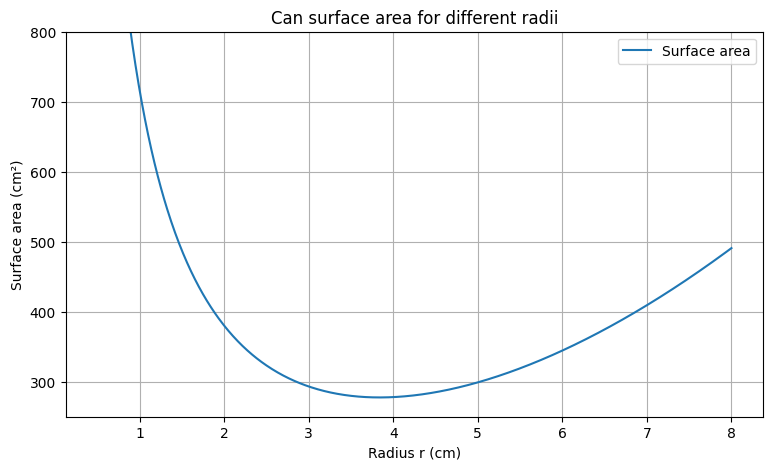

In [37]:
import numpy as np
import matplotlib.pyplot as plt

def area(r):
    return 710 / r + 2 * np.pi * r**2

r_values = np.linspace(0.5, 8, 800)
area_values = area(r_values)



plt.figure(figsize=(9, 5))
plt.plot(r_values, area_values, label="Surface area")
plt.xlabel("Radius r (cm)")
plt.ylabel("Surface area (cm²)")
plt.title("Can surface area for different radii")
plt.ylim(250, 800)  # Limits the display so the valley is easier to see
plt.grid(True)
plt.legend()
plt.show()

The graph above shows that possible starting point can be r = 4 in order to find minima. We can also find second order derivative of this function:

$A''(r)=\frac{1420}{r^3}+4\pi$

We can see that its always positive which shows that the graph is going to curve upwards only.

Radius: 3.837 cm
Height: 7.674 cm
Surface area: 277.545 cm^2
Material saved: 45.455 cm^2
Percent saved: 14.07%


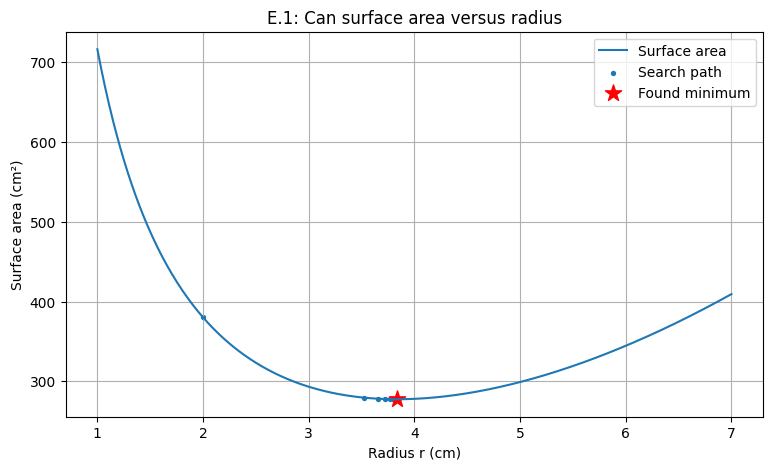

In [44]:
import math
import numpy as np
import torch
import matplotlib.pyplot as plt

# Surface area as a function of radius
def area(r):
    return 710 / r + 2 * math.pi * r**2

# Starting radius, step size, and number of steps
r = torch.tensor(2.0, dtype=torch.float64, requires_grad=True)
eta = 0.01
n_steps = 1000

# Save the search path so we can plot it
trajectory_r = [r.item()]
trajectory_area = [area(r).item()]

for _ in range(n_steps):
    current_area = area(r)
    current_area.backward()  # PyTorch calculates the slope

    with torch.no_grad():
        r -= eta * r.grad     # move downhill
        r.grad.zero_()        # clear the previous slope

    trajectory_r.append(r.item())
    trajectory_area.append(area(r).item())

# Calculate the corresponding height and final area
radius = r.item()
height = 355 / (math.pi * radius**2)
minimum_area = area(r).item()

print(f"Radius: {radius:.3f} cm")
print(f"Height: {height:.3f} cm")
print(f"Surface area: {minimum_area:.3f} cm^2")
print(f"Material saved: {323 - minimum_area:.3f} cm^2")
print(f"Percent saved: {(323 - minimum_area) / 323 * 100:.2f}%")

# Plot the objective function and the gradient descent path
r_values = np.linspace(1, 7, 500)
area_values = 710 / r_values + 2 * math.pi * r_values**2

plt.figure(figsize=(9, 5))
plt.plot(r_values, area_values, label="Surface area")
plt.scatter(trajectory_r, trajectory_area, s=8, label="Search path")
plt.scatter(radius, minimum_area, color="red", marker="*", s=150,
            label="Found minimum")
plt.xlabel("Radius r (cm)")
plt.ylabel("Surface area (cm²)")
plt.title("E.1: Can surface area versus radius")
plt.grid(True)
plt.legend()
plt.show()

I tried eta as [0.1, 0.01, 0.001], I found out 0.01 to be the best suited eta value here. 0.1 overshoots and 0.001 is slower.

# Task F

F1:

(a) Gradient Descent is a reasonable approach for finding local minima because it can be used when a minimum is difficult to find by hand. The gradient calculation can be automated using PyTorch. The basic idea is to find the slope at a particular point and, based on that, update the position so that eventually we move toward a minimum. Since we have to move to the bottom of the valley, we subtract a step-size-scaled gradient from the current position.


(b) Auto differenciation is very useful because it gets really tough to calculate the differenciation of some reaclly complex functions. It uses chain rule and hence makes it easy to calculate the differenciation in more efficient way.

(c) TensorFlow by Google is currently very popular, epecially in industry because it is more production friendly.

(d) Yes, I think i have understood the idea presented of auto-differenciation. The basic principle behind it is the use of chain rule to calculate the complex differenctiaiton. It basically divides the complex computation into simple elements and then compute them together to give the final answer.

(e) I personally found this assignment to be very enlightening. It gave the glimps of how ANN or model workd under the hood. It also focused on the optimization problem which can be used in real life problems. I personally enjoyed the can problem very much.

(f) The manual calculation part felt a bit unnecesory at first but later I realised the importance of it. It helped me grasp the whole concept better.

(g) I would like to keep it same. It is a bit challenging (especially with the tight deadline) but equally enriching.

(h) No, I did not spend more than 20 hrs
